# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [33]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [34]:
AviationData_Copy = pd.read_csv("AviationData_Cleaned.csv")
AviationData_Copy.shape

(935, 36)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [35]:
df = AviationData_Copy.copy()

# Ensure the passenger count and injury rate are numeric
df["Total.Passengers"] = pd.to_numeric(
    df["Total.Passengers"], errors="coerce"
)
df["Fatal_Serious_Injury_Rate"] = pd.to_numeric(
    df["Fatal_Serious_Injury_Rate"], errors="coerce"
)

# Keep records with valid passenger counts and injury rates
df = df[
    (df["Total.Passengers"] > 0) &
    df["Fatal_Serious_Injury_Rate"].notna() &
    df["Make"].notna() &
    df["Model"].notna()
].copy()

# Separate small and large aircraft using the 20-passenger threshold
small_planes = df[df["Total.Passengers"] < 20].copy()
large_planes = df[df["Total.Passengers"] >= 20].copy()

print("Small aircraft records:", len(small_planes))
print("Large aircraft records:", len(large_planes))

Small aircraft records: 730
Large aircraft records: 163


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [36]:
# Calculate mean injury rate and number of records per make
small_make_stats = (
    small_planes.groupby("Make")["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
    .query("count >= 10")
    .sort_values("mean")
)

large_make_stats = (
    large_planes.groupby("Make")["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
    .query("count >= 10")
    .sort_values("mean")
)

# Select the 15 makes with the lowest mean injury rates
small_top15 = small_make_stats.head(15)
large_top15 = large_make_stats.head(15)

print("Small aircraft makes:")
display(small_top15)

print("Large aircraft makes:")
display(large_top15)

Small aircraft makes:


,mean,count
Make,,
cirrus design corp,0.133333,10
boeing,0.187500,26
air tractor inc,0.230769,13
piper,0.247225,142
beech,0.268216,83
dehavilland,0.301403,43
cessna,0.308526,340
de havilland,0.401261,16


Large aircraft makes:


,mean,count
Make,,
embraer,0.051070,29
boeing,0.058886,97
airbus,0.067967,34


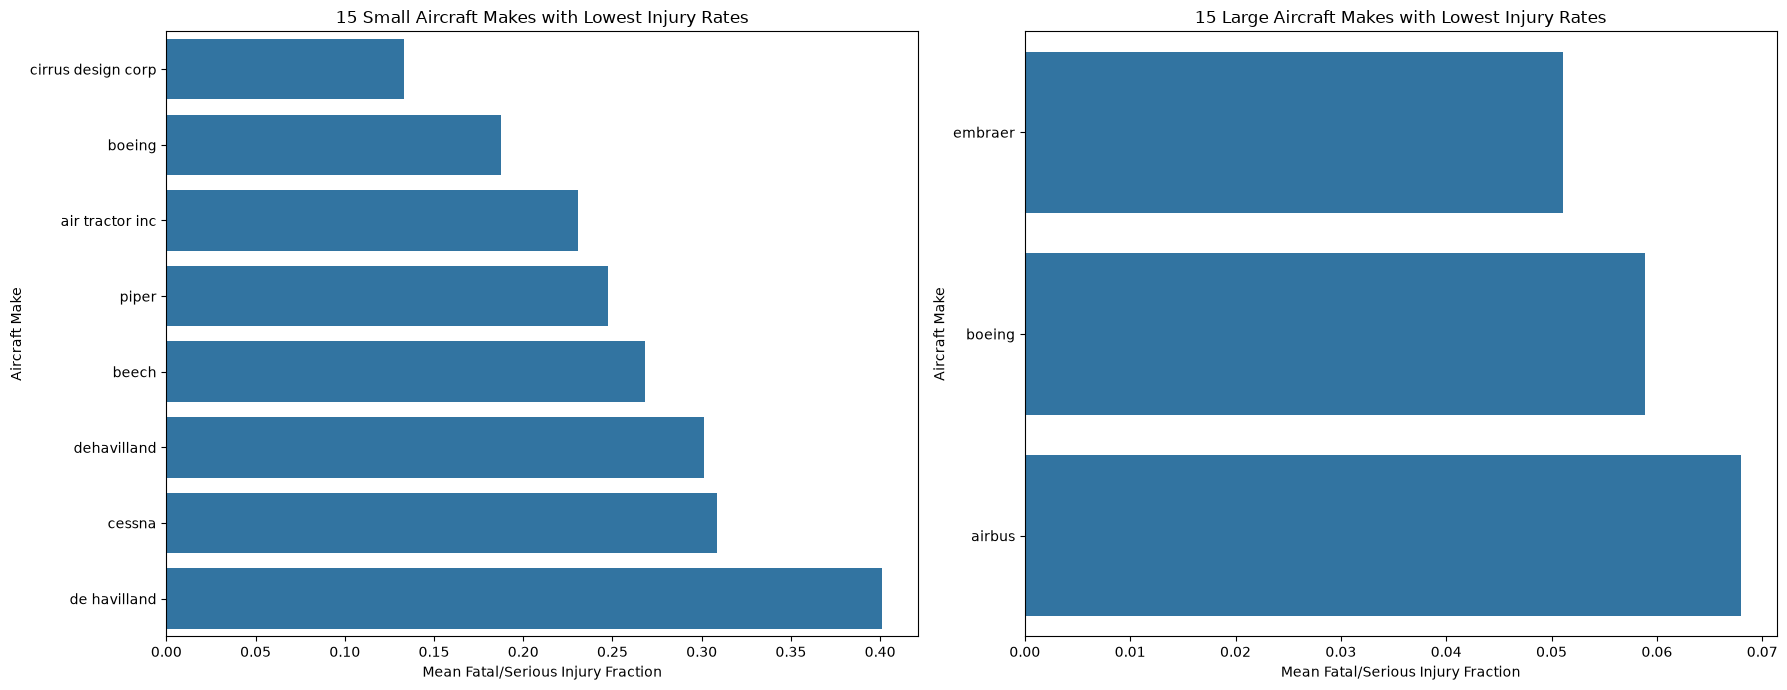

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_top15.reset_index(),
    x="mean", y="Make", ax=axes[0]
)
axes[0].set_title("15 Small Aircraft Makes with Lowest Injury Rates")
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].set_ylabel("Aircraft Make")

sns.barplot(
    data=large_top15.reset_index(),
    x="mean", y="Make", ax=axes[1]
)
axes[1].set_title("15 Large Aircraft Makes with Lowest Injury Rates")
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

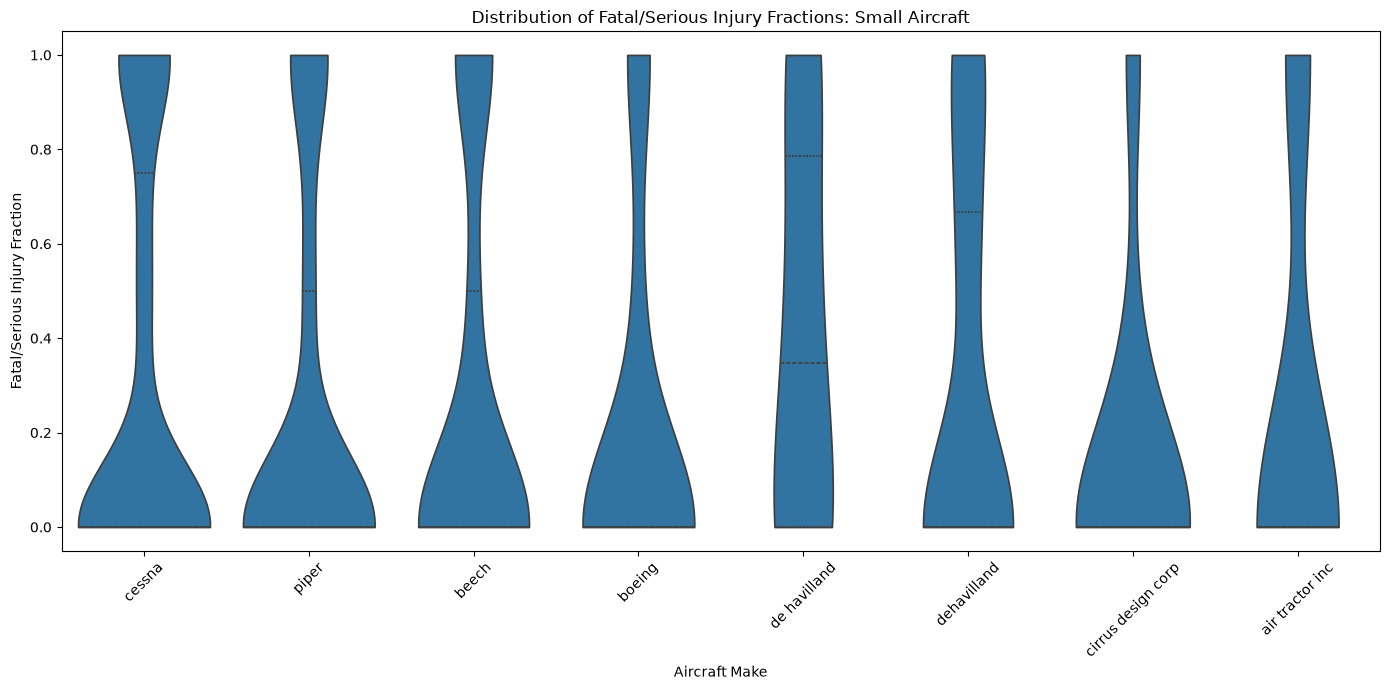

In [38]:
small_top10_makes = small_make_stats.head(10).index

small_violin_data = small_planes[
    small_planes["Make"].isin(small_top10_makes)
]

plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_violin_data,
    x="Make",
    y="Fatal_Serious_Injury_Rate",
    inner="quartile",
    cut=0
)

plt.title("Distribution of Fatal/Serious Injury Fractions: Small Aircraft")
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

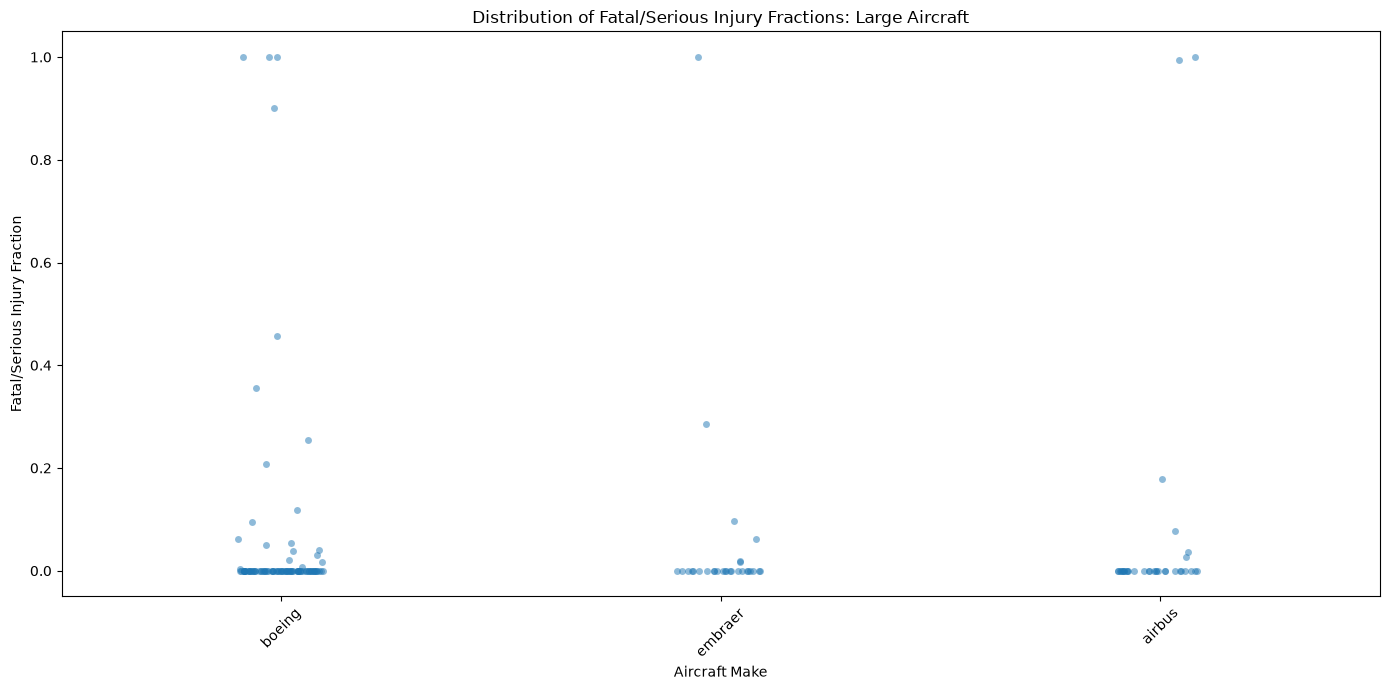

In [39]:
large_top10_makes = large_make_stats.head(10).index

large_strip_data = large_planes[
    large_planes["Make"].isin(large_top10_makes)
]

plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_strip_data,
    x="Make",
    y="Fatal_Serious_Injury_Rate",
    jitter=True,
    alpha=0.5
)

plt.title("Distribution of Fatal/Serious Injury Fractions: Large Aircraft")
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [40]:
destruction_df = df[
    df["Aircraft_destroyed"].notna()
].copy()

# Calculate destruction rates for small aircraft
small_destruction = (
    destruction_df[destruction_df["Total.Passengers"] < 20]
    .groupby("Make")["Aircraft_destroyed"]
    .agg(
        records="count",
        destroyed=lambda x: (x == "Yes").sum()
    )
)

small_destruction = small_destruction[
    small_destruction["records"] >= 10
]
small_destruction["Destruction_Rate"] = (
    small_destruction["destroyed"] / small_destruction["records"]
)
small_destruction = small_destruction.sort_values("Destruction_Rate").head(15)

# Calculate destruction rates for large aircraft
large_destruction = (
    destruction_df[destruction_df["Total.Passengers"] >= 20]
    .groupby("Make")["Aircraft_destroyed"]
    .agg(
        records="count",
        destroyed=lambda x: (x == "Yes").sum()
    )
)

large_destruction = large_destruction[
    large_destruction["records"] >= 10
]
large_destruction["Destruction_Rate"] = (
    large_destruction["destroyed"] / large_destruction["records"]
)
large_destruction = large_destruction.sort_values("Destruction_Rate").head(15)

print("15 small aircraft makes with the lowest destruction rates:")
display(small_destruction)

print("15 large aircraft makes with the lowest destruction rates:")
display(large_destruction)

15 small aircraft makes with the lowest destruction rates:


,records,destroyed,Destruction_Rate
Make,,,
dehavilland,43,2,0.046512
piper,142,13,0.091549
cessna,340,39,0.114706
air tractor inc,13,2,0.153846
beech,83,13,0.156627
de havilland,16,3,0.187500
boeing,26,5,0.192308
cirrus design corp,10,2,0.200000


15 large aircraft makes with the lowest destruction rates:


,records,destroyed,Destruction_Rate
Make,,,
embraer,29,1,0.034483
boeing,97,4,0.041237
airbus,34,2,0.058824


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

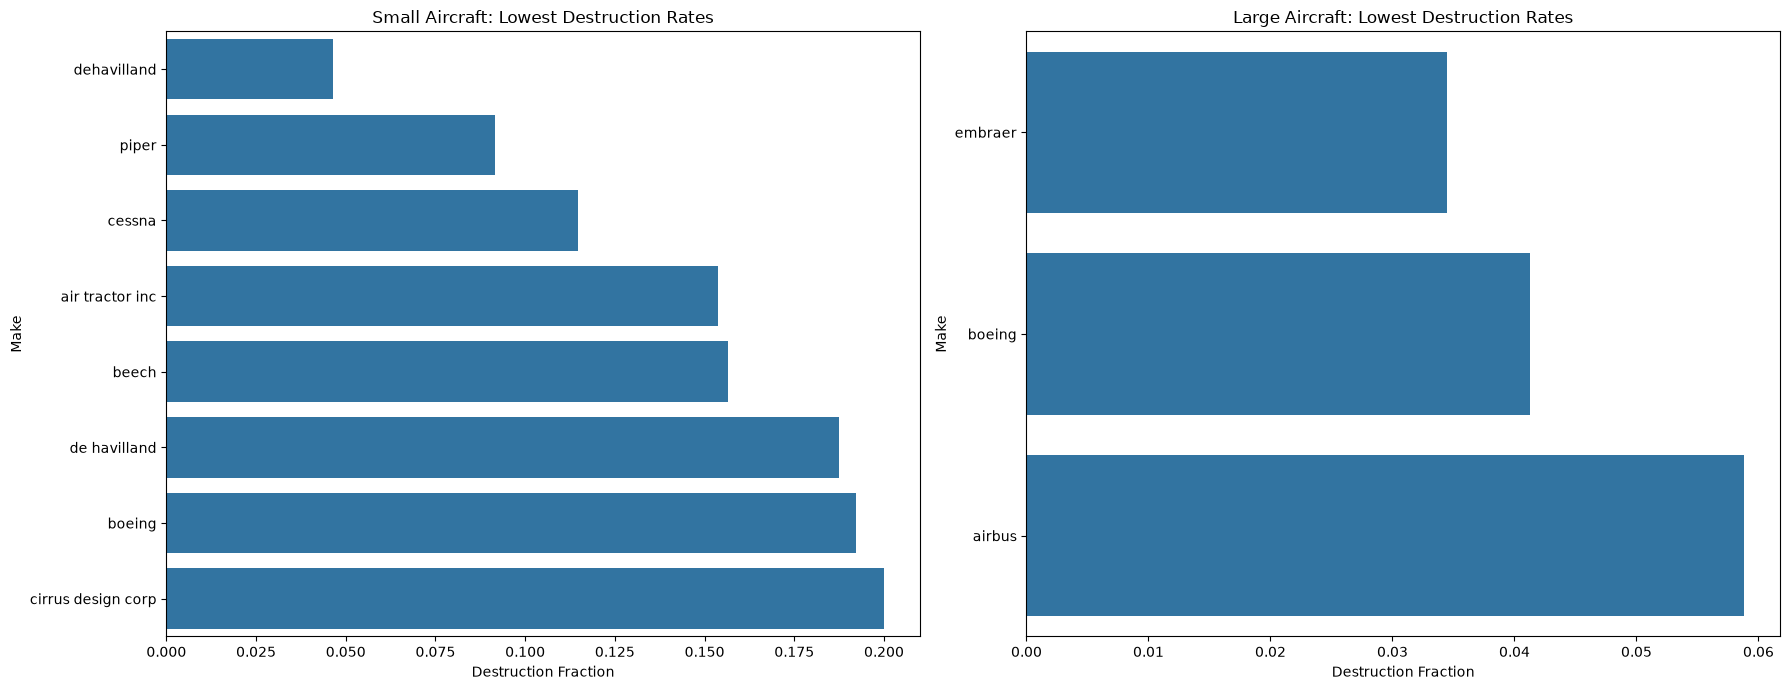

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_destruction.reset_index(),
    x="Destruction_Rate",
    y="Make",
    ax=axes[0]
)
axes[0].set_title("Small Aircraft: Lowest Destruction Rates")
axes[0].set_xlabel("Destruction Fraction")

sns.barplot(
    data=large_destruction.reset_index(),
    x="Destruction_Rate",
    y="Make",
    ax=axes[1]
)
axes[1].set_title("Large Aircraft: Lowest Destruction Rates")
axes[1].set_xlabel("Destruction Fraction")

plt.tight_layout()
plt.show()

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [42]:
# Create a unique airplane type using Make and Model
AviationData_Copy["Make_Model"] = (
    AviationData_Copy["Make"].astype(str) + " " +
    AviationData_Copy["Model"].astype(str)
)


large_planes = AviationData_Copy[
    AviationData_Copy["Total.Passengers"] >= 20
].copy()

# Calculate statistics for large airplane types
large_model_stats = (
    large_planes.groupby("Make_Model")["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
)

large_model_stats = large_model_stats[
    large_model_stats["count"] >= 10
].sort_values("mean")

# Display the results
display(large_model_stats)

,mean,count
Make_Model,,
boeing 737,0.165822,20


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

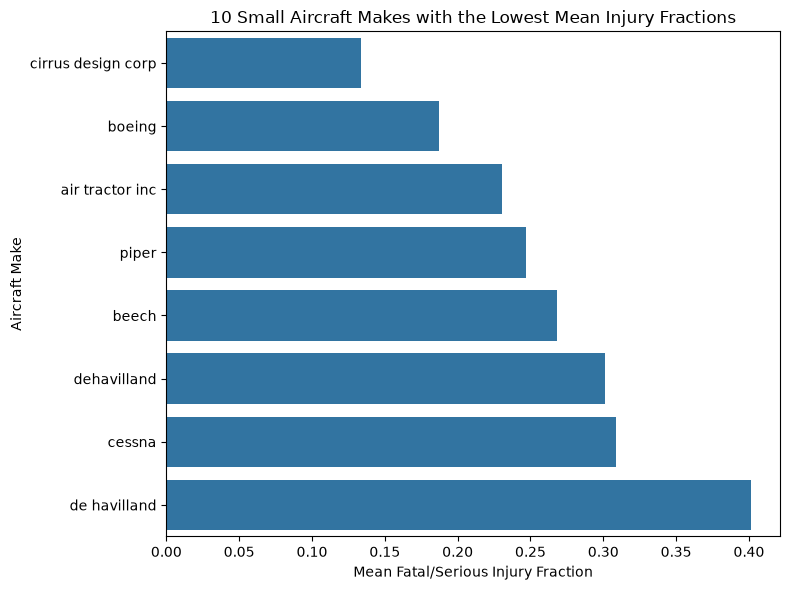

In [43]:
# Calculate the mean injury fraction for each make
small_make_stats = (
    small_planes.groupby("Make")["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
)

# Keep makes with at least 10 records
small_make_stats = small_make_stats[
    small_make_stats["count"] >= 10
]

# Select the 10 makes with the lowest mean injury fractions
small_top10 = small_make_stats.sort_values("mean").head(10).reset_index()

# Plot the results
plt.figure(figsize=(8, 6))

sns.barplot(data=small_top10, x="mean", y="Make")

plt.title("10 Small Aircraft Makes with the Lowest Mean Injury Fractions")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Make")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types

The analysis compared small and large airplane models based on the mean fraction of passengers who suffered fatal or serious injuries in recorded aviation accidents. Small airplanes were classified as carrying fewer than 20 passengers, while large airplanes were classified as carrying 20 or more passengers. Only models with at least 10 accident records were included to improve the reliability of the calculated averages.

For small airplanes, the results showed differences in injury fractions across makes and models. The makes with the lowest mean fatal/serious injury fractions had fewer recorded fatal or serious injuries relative to the number of people aboard, on average. However, individual accidents may still have high injury fractions, as shown by the distribution plots.

For large airplanes, fewer models met the minimum requirement of 10 accident records in the current dataset. Therefore, the results for large airplanes were limited and should be interpreted cautiously. A small sample of eligible models makes it difficult to draw reliable comparisons between different aircraft types.

Overall, aircraft models with lower mean fatal/serious injury fractions may be worth further investigation. However, these results describe injury outcomes among recorded accidents and do not necessarily indicate the overall safety of an aircraft model. The number of observations, variation in injury fractions, aircraft usage, and operating conditions should be considered before making recommendations to the insurer.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [44]:
# Prepare the data
df = AviationData_Copy.copy()

# Convert the injury rate to numeric
df["Fatal_Serious_Injury_Rate"] = pd.to_numeric(
    df["Fatal_Serious_Injury_Rate"], errors="coerce"
)

# Convert aircraft destruction status into numbers
# Yes = 1, No = 0, missing = NaN
df["Destroyed_Flag"] = df["Aircraft_destroyed"].map(
    {"Yes": 1, "No": 0}
)

# Clean the two categorical variables
for col in ["Weather.Condition", "Broad.phase.of.flight"]:
    df[col] = df[col].astype("string").str.strip().str.upper()

# Check the categories
print(df["Weather.Condition"].value_counts(dropna=False))
print(df["Broad.phase.of.flight"].value_counts(dropna=False))

Weather.Condition
VMC     710
<NA>    129
IMC      96
Name: count, dtype: Int64
Broad.phase.of.flight
<NA>        933
APPROACH      1
TAKEOFF       1
Name: count, dtype: Int64


In [45]:
#weather conditions
weather_stats = (
    df.groupby("Weather.Condition")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injury_Rate", "mean"),
        Injury_Records=("Fatal_Serious_Injury_Rate", "count"),
        Destruction_Rate=("Destroyed_Flag", "mean"),
        Destruction_Records=("Destroyed_Flag", "count")
    )
)

weather_stats = weather_stats[
    (weather_stats["Injury_Records"] >= 10) &
    (weather_stats["Destruction_Records"] >= 10)
].sort_values("Mean_Injury_Rate")

display(weather_stats.round(3))

,Mean_Injury_Rate,Injury_Records,Destruction_Rate,Destruction_Records
Weather.Condition,,,,
VMC,0.214,697,0.085,710
IMC,0.420,95,0.188,96


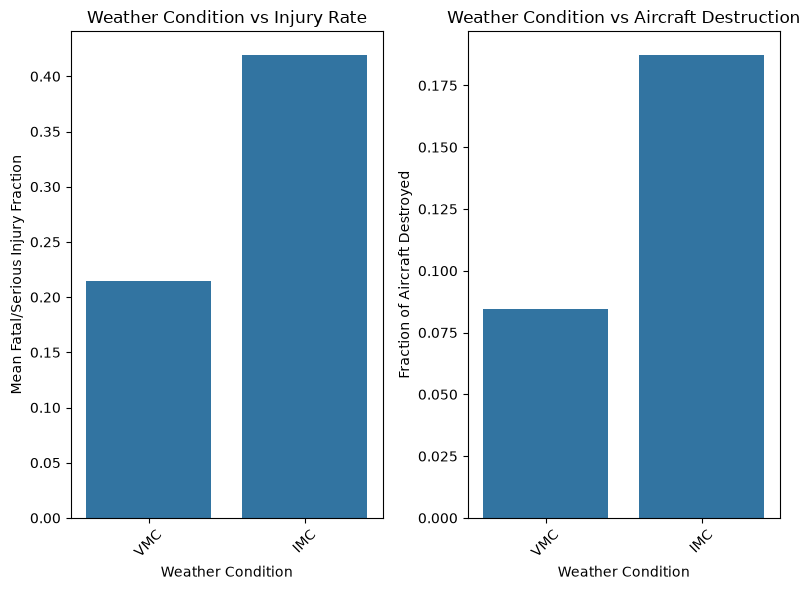

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(8, 6))

sns.barplot(
    data=weather_stats.reset_index(),
    x="Weather.Condition",
    y="Mean_Injury_Rate",
    ax=axes[0]
)
axes[0].set_title("Weather Condition vs Injury Rate")
axes[0].set_xlabel("Weather Condition")
axes[0].set_ylabel("Mean Fatal/Serious Injury Fraction")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=weather_stats.reset_index(),
    x="Weather.Condition",
    y="Destruction_Rate",
    ax=axes[1]
)
axes[1].set_title("Weather Condition vs Aircraft Destruction")
axes[1].set_xlabel("Weather Condition")
axes[1].set_ylabel("Fraction of Aircraft Destroyed")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The analysis investigated the relationship between weather conditions and aircraft damage and passenger injuries. The mean fatal/serious injury fraction was calculated for each weather category, alongside the fraction of aircraft recorded as destroyed.

The results showed that **IMC** had the highest observed mean injury fraction, while **VMC** had the lowest.

These results suggest that injury outcomes and aircraft destruction may vary across recorded weather conditions. However, the findings do not establish that weather alone caused the differences. Other factors, including the phase of flight, aircraft type, pilot actions and accident severity, may also influence the outcomes. Some records may also have missing or inaccurately reported weather information.

In [47]:
# Factor 2 Number of Engines
engine_stats = (
    AviationData_Copy.groupby("Number.of.Engines")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injury_Rate", "mean"),
        Injury_Records=("Fatal_Serious_Injury_Rate", "count"),
        Destruction_Rate=("Aircraft_destroyed",
                          lambda x: (x == "Yes").sum() / x.notna().sum()),
        Destruction_Records=("Aircraft_destroyed", "count")
    )
)

display(engine_stats.round(3))

,Mean_Injury_Rate,Injury_Records,Destruction_Rate,Destruction_Records
Number.of.Engines,,,,
1.0,0.282,472,0.102,472
2.0,0.171,351,0.080,377
3.0,0.031,2,0.000,3
4.0,0.084,13,0.062,16


In [48]:
print(AviationData_Copy["Number.of.Engines"].value_counts(dropna=False))

Number.of.Engines
1.0    472
2.0    377
NaN     67
4.0     16
3.0      3
Name: count, dtype: int64


In [49]:
engine_stats = (
    AviationData_Copy.groupby("Number.of.Engines")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injury_Rate", "mean"),
        Injury_Records=("Fatal_Serious_Injury_Rate", "count"),
        Destruction_Rate=("Aircraft_destroyed",
                          lambda x: (x == "Yes").sum() / x.notna().sum()),
        Destruction_Records=("Aircraft_destroyed", "count")
    )
)

display(engine_stats.round(3))

,Mean_Injury_Rate,Injury_Records,Destruction_Rate,Destruction_Records
Number.of.Engines,,,,
1.0,0.282,472,0.102,472
2.0,0.171,351,0.080,377
3.0,0.031,2,0.000,3
4.0,0.084,13,0.062,16


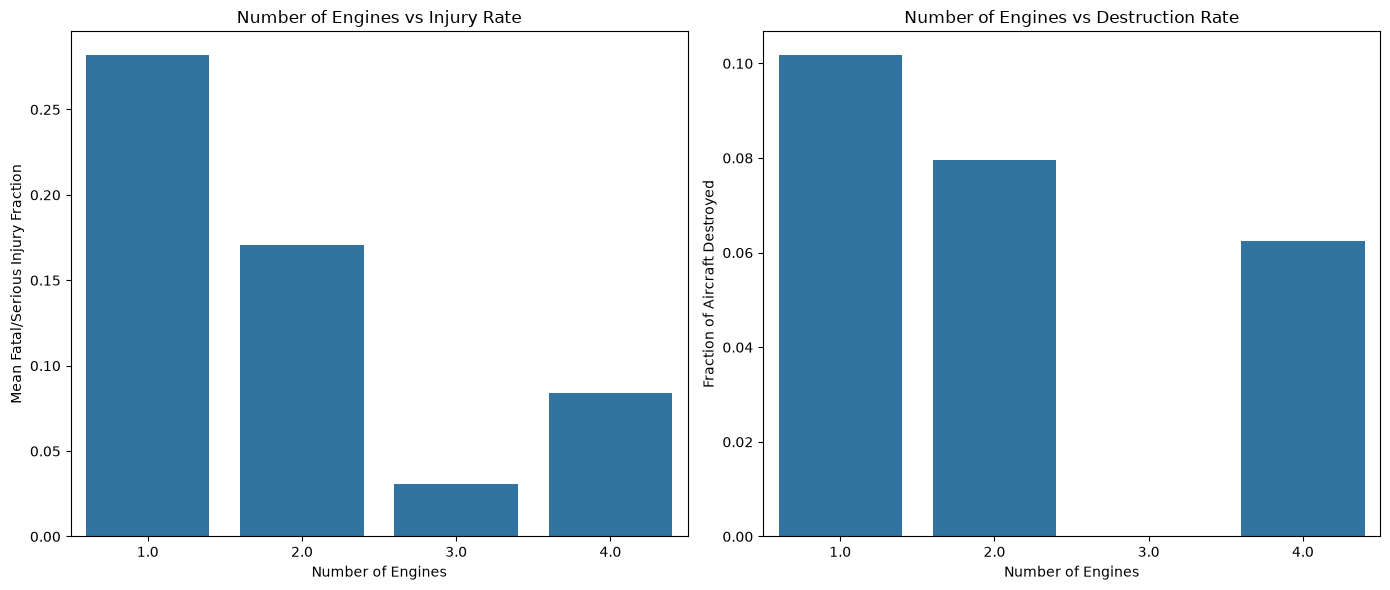

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    x=engine_stats.index.astype(str),
    y=engine_stats["Mean_Injury_Rate"],
    ax=axes[0]
)
axes[0].set_title("Number of Engines vs Injury Rate")
axes[0].set_xlabel("Number of Engines")
axes[0].set_ylabel("Mean Fatal/Serious Injury Fraction")

sns.barplot(
    x=engine_stats.index.astype(str),
    y=engine_stats["Destruction_Rate"],
    ax=axes[1]
)
axes[1].set_title("Number of Engines vs Destruction Rate")
axes[1].set_xlabel("Number of Engines")
axes[1].set_ylabel("Fraction of Aircraft Destroyed")

plt.tight_layout()
plt.show()

### Discussion: Number of Engines

The analysis investigated the relationship between the number of engines and aircraft safety outcomes. The mean fatal/serious injury fraction and aircraft destruction rate were calculated for aircraft with different numbers of engines.

The results showed that aircraft with **3 engines** had the lowest mean fatal/serious injury fraction, while aircraft with **1 engine** had the highest. 

These results indicate that injury outcomes and aircraft destruction rates may differ across engine configurations in the recorded accident data. However, the results do not prove that the number of engines directly determines safety. Aircraft size, model, flight purpose, operating conditions and accident severity may also influence the outcomes. Categories with fewer observations should be interpreted cautiously.


### OVERALL DECISION
Recommendations Based on Aircraft Destruction and Injury Rates

For small aircraft, De Havilland had the lowest destruction rate at approximately 4.65%, followed by Piper at 9.15% and Cessna at 11.47%. In the injury analysis, Cirrus Design Corp had the lowest mean fatal/serious injury fraction at 13.33%, followed by Boeing at 18.75%. These results suggest that De Havilland, Piper, and Cessna may be worth further consideration based on destruction rates, while Cirrus Design Corp and Piper may be worth examining based on injury outcomes.

For large aircraft, Embraer had the lowest mean fatal/serious injury fraction at approximately 5.08%, followed by Boeing at 5.89% and Airbus at 7.45%. These findings suggest that Embraer performed relatively well in the available accident records for injury outcomes. However, further comparison of destruction rates is needed before making a recommendation based on both measures.

Overall, I recommend considering aircraft makes that demonstrate both low destruction rates and low fatal/serious injury fractions. The results should be interpreted cautiously because the dataset contains only accident records, some makes have relatively few observations, and factors such as accident severity, operating conditions, aircraft age, and maintenance history may influence the outcomes. A more complete assessment using flight hours, fleet size, and the number of flights would be needed before making a reliable aircraft safety recommendation.